# Make Clean Tables 

Looking to process the raw tables and make a clean table to use for analysis

In [1]:
import duckdb
import pandas as pd

import plotly.io as pio

#charts are saved as small static images so the notebook stays light in git
#comment this out while exploring to get zoom and hover back
pio.renderers.default = "png"

In [2]:
#start connection
con = duckdb.connect("../data/grid.duckdb")


#check connection
con.sql("SHOW TABLES")

┌───────────────┐
│     name      │
│    varchar    │
├───────────────┤
│ demand_clean  │
│ demand_issues │
│ demand_wide   │
│ eia_raw       │
│ model_hourly  │
│ weather_raw   │
│ weather_wide  │
└───────────────┘

In [3]:
#set the timezone to be 'UTC' to match data
con.sql("SET TimeZone = 'UTC'")

In [4]:
#quick look at databases 
con.sql("DESCRIBE eia_raw"), con.sql("DESCRIBE weather_raw")

(┌─────────────┬──────────────────────────┬─────────┬─────────┬─────────┬─────────┐
 │ column_name │       column_type        │  null   │   key   │ default │  extra  │
 │   varchar   │         varchar          │ varchar │ varchar │ varchar │ varchar │
 ├─────────────┼──────────────────────────┼─────────┼─────────┼─────────┼─────────┤
 │ period_utc  │ TIMESTAMP WITH TIME ZONE │ YES     │ NULL    │ NULL    │ NULL    │
 │ respondent  │ VARCHAR                  │ YES     │ NULL    │ NULL    │ NULL    │
 │ type        │ VARCHAR                  │ YES     │ NULL    │ NULL    │ NULL    │
 │ value_mwh   │ DOUBLE                   │ YES     │ NULL    │ NULL    │ NULL    │
 └─────────────┴──────────────────────────┴─────────┴─────────┴─────────┴─────────┘,
 ┌──────────────────────┬──────────────────────────┬─────────┬─────────┬─────────┬─────────┐
 │     column_name      │       column_type        │  null   │   key   │ default │  extra  │
 │       varchar        │         varchar          │ varc

#### Difference between 'D' and 'DF'
- Lets first look at the difference of 72 between 'D' and 'DF' columns. 

In [5]:
#first since 'D' has everything we can use that as the partner match to 'DF' to find the missing 72
con.sql("""
    WITH d_hours AS (
        SELECT period_utc FROM eia_raw WHERE type = 'D'
    ),
    df_hours AS (
        SELECT period_utc FROM eia_raw WHERE type = 'DF'
    )
    SELECT d_hours.period_utc
    FROM d_hours
    LEFT JOIN df_hours ON d_hours.period_utc = df_hours.period_utc
    WHERE df_hours.period_utc IS NULL
    ORDER BY d_hours.period_utc
""")

┌──────────────────────────┐
│        period_utc        │
│ timestamp with time zone │
├──────────────────────────┤
│ 2021-09-16 08:00:00+00   │
│ 2021-09-16 09:00:00+00   │
│ 2021-09-16 10:00:00+00   │
│ 2021-09-16 11:00:00+00   │
│ 2021-09-16 12:00:00+00   │
│ 2021-09-16 13:00:00+00   │
│ 2021-09-16 14:00:00+00   │
│ 2021-09-16 15:00:00+00   │
│ 2021-09-16 16:00:00+00   │
│ 2021-09-16 17:00:00+00   │
│           ·              │
│           ·              │
│           ·              │
│ 2026-08-09 22:00:00+00   │
│ 2026-08-09 23:00:00+00   │
│ 2026-08-10 00:00:00+00   │
│ 2026-08-10 01:00:00+00   │
│ 2026-08-10 02:00:00+00   │
│ 2026-08-10 03:00:00+00   │
│ 2026-08-10 04:00:00+00   │
│ 2026-08-10 05:00:00+00   │
│ 2026-08-10 06:00:00+00   │
│ 2026-08-10 07:00:00+00   │
└──────────────────────────┘
     72 rows (20 shown)   

Okay, took a bit to get that but what is happening:  

    - First WITH is creating temporary lists as the given games using the period for each type which is why I can call d_hours.period_utc later.  

    - the left join of d to df goes through d and trys to find the same hour in df -> this is why we use left join here so it can use the d type   

    - The final where keeps just the corresponding NULL matches so if there is no match between d and df that is what gets shown.  
Check that there is 72 since we know that is what should be the total

We could also check the difference between each value. Since the data is given every hour we can check the lag between points and see where it is greater than 1 to try and find the missing times.   

Another and maybe the most general to check the range of values for the time we want. Can use the range on the period to generate times with the given timestampz from when we pulled the data and stopped the pull by the known 1 hour. From there we can build it the same was as above to find the hours that have no match to df. This is essentially the same as using 'D' but more general as it can apply to any data range or database as needed. 

In [6]:
#get all hours
con.sql("""
    SELECT range AS period_utc
    FROM range(TIMESTAMPTZ '2021-01-01 00:00:00+00',
               TIMESTAMPTZ '2026-09-01 00:00:00+00',
               INTERVAL 1 HOUR)
""")

┌──────────────────────────┐
│        period_utc        │
│ timestamp with time zone │
├──────────────────────────┤
│ 2021-01-01 00:00:00+00   │
│ 2021-01-01 01:00:00+00   │
│ 2021-01-01 02:00:00+00   │
│ 2021-01-01 03:00:00+00   │
│ 2021-01-01 04:00:00+00   │
│ 2021-01-01 05:00:00+00   │
│ 2021-01-01 06:00:00+00   │
│ 2021-01-01 07:00:00+00   │
│ 2021-01-01 08:00:00+00   │
│ 2021-01-01 09:00:00+00   │
│           ·              │
│           ·              │
│           ·              │
│ 2022-02-21 06:00:00+00   │
│ 2022-02-21 07:00:00+00   │
│ 2022-02-21 08:00:00+00   │
│ 2022-02-21 09:00:00+00   │
│ 2022-02-21 10:00:00+00   │
│ 2022-02-21 11:00:00+00   │
│ 2022-02-21 12:00:00+00   │
│ 2022-02-21 13:00:00+00   │
│ 2022-02-21 14:00:00+00   │
│ 2022-02-21 15:00:00+00   │
└──────────────────────────┘
           ? rows         
   (>9999 rows, 20 shown)  

In [7]:
#now pair it with CTE as before to match the missing rows
con.sql("""
    WITH all_hours AS (
        SELECT range AS period_utc
        FROM range(TIMESTAMPTZ '2021-01-01 00:00:00+00',
                   TIMESTAMPTZ '2026-09-01 00:00:00+00',
                   INTERVAL 1 HOUR)
    ),
    df_hours AS (
        SELECT period_utc AS hours FROM eia_raw WHERE type = 'DF'
    )
    SELECT all_hours.period_utc
    FROM all_hours
    LEFT JOIN df_hours ON all_hours.period_utc = df_hours.hours
    WHERE df_hours.hours IS NULL
    ORDER BY all_hours.period_utc
""")

┌──────────────────────────┐
│        period_utc        │
│ timestamp with time zone │
├──────────────────────────┤
│ 2021-09-16 08:00:00+00   │
│ 2021-09-16 09:00:00+00   │
│ 2021-09-16 10:00:00+00   │
│ 2021-09-16 11:00:00+00   │
│ 2021-09-16 12:00:00+00   │
│ 2021-09-16 13:00:00+00   │
│ 2021-09-16 14:00:00+00   │
│ 2021-09-16 15:00:00+00   │
│ 2021-09-16 16:00:00+00   │
│ 2021-09-16 17:00:00+00   │
│           ·              │
│           ·              │
│           ·              │
│ 2026-08-09 22:00:00+00   │
│ 2026-08-09 23:00:00+00   │
│ 2026-08-10 00:00:00+00   │
│ 2026-08-10 01:00:00+00   │
│ 2026-08-10 02:00:00+00   │
│ 2026-08-10 03:00:00+00   │
│ 2026-08-10 04:00:00+00   │
│ 2026-08-10 05:00:00+00   │
│ 2026-08-10 06:00:00+00   │
│ 2026-08-10 07:00:00+00   │
└──────────────────────────┘
     72 rows (20 shown)   

Also get 72 here. 

#### Seeing all 72 rows
The preview above cuts the middle out. Three ways to actually see what's missing:
1. `.show(max_rows=...)` prints every row
2. group by date so 72 rows become a few
3. the `LAG()` gap check from earlier, which gives one row per gap

In [8]:
#1. print every row instead of the shortened preview
con.sql("""
    WITH d_hours AS (
        SELECT period_utc FROM eia_raw WHERE type = 'D'
    ),
    df_hours AS (
        SELECT period_utc FROM eia_raw WHERE type = 'DF'
    )
    SELECT d_hours.period_utc
    FROM d_hours
    LEFT JOIN df_hours ON d_hours.period_utc = df_hours.period_utc
    WHERE df_hours.period_utc IS NULL
    ORDER BY d_hours.period_utc
""").show(max_rows=100)

┌──────────────────────────┐
│        period_utc        │
│ timestamp with time zone │
├──────────────────────────┤
│ 2021-09-16 08:00:00+00   │
│ 2021-09-16 09:00:00+00   │
│ 2021-09-16 10:00:00+00   │
│ 2021-09-16 11:00:00+00   │
│ 2021-09-16 12:00:00+00   │
│ 2021-09-16 13:00:00+00   │
│ 2021-09-16 14:00:00+00   │
│ 2021-09-16 15:00:00+00   │
│ 2021-09-16 16:00:00+00   │
│ 2021-09-16 17:00:00+00   │
│ 2021-09-16 18:00:00+00   │
│ 2021-09-16 19:00:00+00   │
│ 2021-09-16 20:00:00+00   │
│ 2021-09-16 21:00:00+00   │
│ 2021-09-16 22:00:00+00   │
│ 2021-09-16 23:00:00+00   │
│ 2021-09-17 00:00:00+00   │
│ 2021-09-17 01:00:00+00   │
│ 2021-09-17 02:00:00+00   │
│ 2021-09-17 03:00:00+00   │
│ 2021-09-17 04:00:00+00   │
│ 2021-09-17 05:00:00+00   │
│ 2021-09-17 06:00:00+00   │
│ 2021-09-17 07:00:00+00   │
│ 2023-10-25 08:00:00+00   │
│ 2023-10-25 09:00:00+00   │
│ 2023-10-25 10:00:00+00   │
│ 2023-10-25 11:00:00+00   │
│ 2023-10-25 12:00:00+00   │
│ 2023-10-25 13:00:00+00   │
│ 2023-10-25 1

In [9]:
#2. summarize by day instead of listing every hour
con.sql("""
    WITH d_hours AS (
        SELECT period_utc FROM eia_raw WHERE type = 'D'
    ),
    df_hours AS (
        SELECT period_utc FROM eia_raw WHERE type = 'DF'
    )
    SELECT CAST(d_hours.period_utc AS DATE) AS day_utc, COUNT(*) AS n_missing
    FROM d_hours
    LEFT JOIN df_hours ON d_hours.period_utc = df_hours.period_utc
    WHERE df_hours.period_utc IS NULL
    GROUP BY day_utc
    ORDER BY day_utc
""")

┌────────────┬───────────┐
│  day_utc   │ n_missing │
│    date    │   int64   │
├────────────┼───────────┤
│ 2021-09-16 │        16 │
│ 2021-09-17 │         8 │
│ 2023-10-25 │        16 │
│ 2023-10-26 │         8 │
│ 2026-08-09 │        16 │
│ 2026-08-10 │         8 │
└────────────┴───────────┘

In [10]:
#3. one row per gap: compare each DF hour to the one before it
con.sql("""
    WITH df_hours AS (
        SELECT
            period_utc,
            LAG(period_utc) OVER (ORDER BY period_utc) AS prev_hour
        FROM eia_raw
        WHERE type = 'DF'
    )
    SELECT
        prev_hour              AS last_hour_before_gap,
        period_utc             AS first_hour_after_gap,
        period_utc - prev_hour AS gap
    FROM df_hours
    WHERE period_utc - prev_hour > INTERVAL 1 HOUR
    ORDER BY period_utc
""")

┌──────────────────────────┬──────────────────────────┬────────────────┐
│   last_hour_before_gap   │   first_hour_after_gap   │      gap       │
│ timestamp with time zone │ timestamp with time zone │    interval    │
├──────────────────────────┼──────────────────────────┼────────────────┤
│ 2021-09-16 07:00:00+00   │ 2021-09-17 08:00:00+00   │ 1 day 01:00:00 │
│ 2023-10-25 07:00:00+00   │ 2023-10-26 08:00:00+00   │ 1 day 01:00:00 │
│ 2026-08-09 07:00:00+00   │ 2026-08-10 08:00:00+00   │ 1 day 01:00:00 │
└──────────────────────────┴──────────────────────────┴────────────────┘

Three gaps of `1 day 01:00:00`: 25 hours from the last hour before to the first hour after, so 24 missing each (3 × 24 = 72).
Each gap runs 08:00 to 07:00 UTC, which is 01:00 to 24:00 Pacific (daylight time). So each one is **one full Pacific-time day**.

## Now the 49 NULL in 'D'

In [11]:
#this should be easier, see what the dates are for the NULL responses in 'D'
# the value mwh are null but they have date values
con.sql("""
    SELECT period_utc, value_mwh AS demand_mwh
    FROM eia_raw
    WHERE demand_mwh IS NULL AND type = 'D'
    ORDER BY period_utc
""")

┌──────────────────────────┬────────────┐
│        period_utc        │ demand_mwh │
│ timestamp with time zone │   double   │
├──────────────────────────┼────────────┤
│ 2021-09-15 08:00:00+00   │       NULL │
│ 2021-09-15 09:00:00+00   │       NULL │
│ 2021-09-15 10:00:00+00   │       NULL │
│ 2021-09-15 11:00:00+00   │       NULL │
│ 2021-09-15 12:00:00+00   │       NULL │
│ 2021-09-15 13:00:00+00   │       NULL │
│ 2021-09-15 14:00:00+00   │       NULL │
│ 2021-09-15 15:00:00+00   │       NULL │
│ 2021-09-15 16:00:00+00   │       NULL │
│ 2021-09-15 17:00:00+00   │       NULL │
│           ·              │         ·  │
│           ·              │         ·  │
│           ·              │         ·  │
│ 2023-10-24 22:00:00+00   │       NULL │
│ 2023-10-24 23:00:00+00   │       NULL │
│ 2023-10-25 00:00:00+00   │       NULL │
│ 2023-10-25 01:00:00+00   │       NULL │
│ 2023-10-25 02:00:00+00   │       NULL │
│ 2023-10-25 03:00:00+00   │       NULL │
│ 2023-10-25 04:00:00+00   │      

We get 49 rows matching expected NULLs and can see the dates when they appeared. 

In [12]:
#summarize by day, and show the Pacific time so the pattern is easier to see
con.sql("""
    SELECT
        CAST(period_utc AS DATE) AS day_utc,
        COUNT(*) AS n_null,
        MIN(period_utc) AS first_hour_utc,
        MIN(period_utc) AT TIME ZONE 'America/Los_Angeles' AS first_hour_pacific
    FROM eia_raw
    WHERE type = 'D' AND value_mwh IS NULL
    GROUP BY day_utc
    ORDER BY day_utc
""")

┌────────────┬────────┬──────────────────────────┬─────────────────────┐
│  day_utc   │ n_null │      first_hour_utc      │ first_hour_pacific  │
│    date    │ int64  │ timestamp with time zone │      timestamp      │
├────────────┼────────┼──────────────────────────┼─────────────────────┤
│ 2021-09-15 │     16 │ 2021-09-15 08:00:00+00   │ 2021-09-15 01:00:00 │
│ 2021-09-16 │      8 │ 2021-09-16 00:00:00+00   │ 2021-09-15 17:00:00 │
│ 2021-11-07 │      1 │ 2021-11-07 05:00:00+00   │ 2021-11-06 22:00:00 │
│ 2023-10-24 │     16 │ 2023-10-24 08:00:00+00   │ 2023-10-24 01:00:00 │
│ 2023-10-25 │      8 │ 2023-10-25 00:00:00+00   │ 2023-10-24 17:00:00 │
└────────────┴────────┴──────────────────────────┴─────────────────────┘

`AT TIME ZONE 'America/Los_Angeles'` converts a UTC timestamp to Pacific clock time, which is handy for checking whether a gap lines up with a local day.

The 49 NULLs are:
- **2021-09-15** (Pacific): one full day, 24 hours
- **2023-10-24** (Pacific): one full day, 24 hours
- **2021-11-07 05:00 UTC** (10 pm Pacific on Nov 6): a single hour, a few hours before the daylight saving fall-back

Both full days are **the day before** a DF gap (2021-09-16 and 2023-10-25 Pacific). They look like the same reporting outages.

## Lets look at  (possible) outliers  
Lets see if there are some unusual values

In [13]:
#gets min and max for the spread and some general percentiles to see how it spans
con.sql("""
    SELECT MIN(value_mwh) AS min_mwh, MAX(value_mwh) AS max_mwh
    FROM eia_raw
    WHERE type = 'D'
""")

┌─────────┬─────────┐
│ min_mwh │ max_mwh │
│ double  │ double  │
├─────────┼─────────┤
│  3804.0 │ 11537.0 │
└─────────┴─────────┘

In [14]:
con.sql("""
    SELECT
        MIN(value_mwh) AS min_mwh,
        MAX(value_mwh) AS max_mwh,
        quantile_cont(value_mwh, [0.001, 0.01, 0.5, 0.99, 0.999]) AS pctls
    FROM eia_raw
    WHERE type = 'D'
""")

┌─────────┬─────────┬──────────────────────────────────────────────────────────────────┐
│ min_mwh │ max_mwh │                              pctls                               │
│ double  │ double  │                             double[]                             │
├─────────┼─────────┼──────────────────────────────────────────────────────────────────┤
│  3804.0 │ 11537.0 │ [4451.0, 4765.06, 6654.0, 9367.880000000005, 10562.152000000002] │
└─────────┴─────────┴──────────────────────────────────────────────────────────────────┘

The quatiles calculates the given percentiles. 0.5 is the median, 0.01 and 0.99 are the 1% and 99% percentiles and added two extra extremes (99.9 and .1) for comparisons to min and max. 

The max is ~ 1000 mwh greater than the 99.9 and the min is ~600 below the 0.1. In both cases neither really jumps out as being crazy different 

In [15]:
#when were the extremes happening
con.sql("""
    SELECT period_utc, value_mwh
    FROM eia_raw
    WHERE type = 'D' AND value_mwh IS NOT NULL
    ORDER BY value_mwh DESC
    LIMIT 10
""")

┌──────────────────────────┬───────────┐
│        period_utc        │ value_mwh │
│ timestamp with time zone │  double   │
├──────────────────────────┼───────────┤
│ 2025-02-12 16:00:00+00   │   11537.0 │
│ 2024-01-13 19:00:00+00   │   11496.0 │
│ 2024-01-13 18:00:00+00   │   11478.0 │
│ 2024-01-13 20:00:00+00   │   11419.0 │
│ 2024-01-13 17:00:00+00   │   11298.0 │
│ 2025-02-12 17:00:00+00   │   11290.0 │
│ 2024-01-13 21:00:00+00   │   11281.0 │
│ 2024-01-14 02:00:00+00   │   11244.0 │
│ 2025-02-11 16:00:00+00   │   11214.0 │
│ 2025-02-12 15:00:00+00   │   11152.0 │
└──────────────────────────┴───────────┘
  10 rows                    2 columns

In [16]:
con.sql("""
    SELECT period_utc, value_mwh
    FROM eia_raw
    WHERE type = 'D' AND value_mwh IS NOT NULL
    ORDER BY value_mwh ASC
    LIMIT 10
""")

┌──────────────────────────┬───────────┐
│        period_utc        │ value_mwh │
│ timestamp with time zone │  double   │
├──────────────────────────┼───────────┤
│ 2025-10-05 07:00:00+00   │    3804.0 │
│ 2025-10-05 06:00:00+00   │    4098.0 │
│ 2022-09-19 10:00:00+00   │    4270.0 │
│ 2022-10-02 11:00:00+00   │    4286.0 │
│ 2022-10-02 10:00:00+00   │    4288.0 │
│ 2022-10-02 12:00:00+00   │    4303.0 │
│ 2021-09-25 11:00:00+00   │    4340.0 │
│ 2022-10-01 11:00:00+00   │    4347.0 │
│ 2022-10-10 10:00:00+00   │    4349.0 │
│ 2022-09-19 09:00:00+00   │    4352.0 │
└──────────────────────────┴───────────┘
  10 rows                    2 columns

The top and bottom cluster round dates some dates some over some hours (2024-1-13) which hints at some weather demand (or something else) and less like a random glitch. 

In [17]:
#data collected every hour - what are the biggest fluctuations in demand
con.sql("""
    SELECT
        period_utc,
        value_mwh,
        value_mwh - LAG(value_mwh) OVER (ORDER BY period_utc) AS jump
    FROM eia_raw
    WHERE type = 'D'
    ORDER BY ABS(jump) DESC NULLS LAST
    LIMIT 10
""")

┌──────────────────────────┬───────────┬─────────┐
│        period_utc        │ value_mwh │  jump   │
│ timestamp with time zone │  double   │ double  │
├──────────────────────────┼───────────┼─────────┤
│ 2024-01-11 22:00:00+00   │    6005.0 │ -2578.0 │
│ 2024-01-11 23:00:00+00   │    8519.0 │  2514.0 │
│ 2026-01-29 10:00:00+00   │    6874.0 │ -2064.0 │
│ 2021-11-17 21:00:00+00   │    7002.0 │ -1845.0 │
│ 2025-10-05 05:00:00+00   │    4363.0 │ -1765.0 │
│ 2026-01-29 09:00:00+00   │    8938.0 │  1741.0 │
│ 2026-07-20 09:00:00+00   │    4878.0 │ -1568.0 │
│ 2024-08-19 18:00:00+00   │    7866.0 │  1536.0 │
│ 2025-10-05 08:00:00+00   │    5291.0 │  1487.0 │
│ 2022-09-13 05:00:00+00   │    6094.0 │ -1331.0 │
└──────────────────────────┴───────────┴─────────┘
  10 rows                              3 columns

Big drop to jump at 2024-01-11. The postive and negative change are nearly equaly and are back to back hours - this points to a likely glitch here. 

In [18]:
#use lead() to check this
con.sql("""
    WITH demand AS (
        SELECT
            period_utc,
            value_mwh,
            value_mwh - LAG(value_mwh) OVER (ORDER BY period_utc) AS jump_in,
            LEAD(value_mwh) OVER (ORDER BY period_utc) - value_mwh AS jump_out
        FROM eia_raw
        WHERE type = 'D'
    )
    SELECT *
    FROM demand
    WHERE ABS(jump_in) > 1000
      AND ABS(jump_out) > 1000
      AND SIGN(jump_in) != SIGN(jump_out)
    ORDER BY period_utc
""")

┌──────────────────────────┬───────────┬─────────┬──────────┐
│        period_utc        │ value_mwh │ jump_in │ jump_out │
│ timestamp with time zone │  double   │ double  │  double  │
├──────────────────────────┼───────────┼─────────┼──────────┤
│ 2021-11-17 20:00:00+00   │    8847.0 │  1299.0 │  -1845.0 │
│ 2024-01-11 22:00:00+00   │    6005.0 │ -2578.0 │   2514.0 │
│ 2024-08-19 18:00:00+00   │    7866.0 │  1536.0 │  -1300.0 │
│ 2026-01-29 09:00:00+00   │    8938.0 │  1741.0 │  -2064.0 │
│ 2026-07-20 09:00:00+00   │    4878.0 │ -1568.0 │   1112.0 │
└──────────────────────────┴───────────┴─────────┴──────────┘

Okay, so LEAD() is the opposite of LAG() checking what is ahead. So we can compared the in and out jumps using both and see where they are large and not the same sign. The sign switch is important as a glitch is likely to go down then up or up then down meaning it will have a change in sign.   

This way finds 5 times this happens. This number changes depedning on the threshold chosen (1000 is shown). This seems like a good number as therwe are not to many and it is about the same jump from the 99% to the 99.9% percentile. This doesn't guarantee they are glitches but below this threshold we have to consider more possibilities and it become less likely the lower the threshold. In this the most obvious is the largest jump we saw eariler

In [19]:
#look at these
con.sql("""
    SELECT period_utc, value_mwh
    FROM eia_raw
    WHERE type = 'D'
      AND period_utc BETWEEN '2024-01-11 12:00:00+00' AND '2024-01-12 02:00:00+00'
    ORDER BY period_utc
""")

┌──────────────────────────┬───────────┐
│        period_utc        │ value_mwh │
│ timestamp with time zone │  double   │
├──────────────────────────┼───────────┤
│ 2024-01-11 12:00:00+00   │    7264.0 │
│ 2024-01-11 13:00:00+00   │    7564.0 │
│ 2024-01-11 14:00:00+00   │    8127.0 │
│ 2024-01-11 15:00:00+00   │    8799.0 │
│ 2024-01-11 16:00:00+00   │    9174.0 │
│ 2024-01-11 17:00:00+00   │    9175.0 │
│ 2024-01-11 18:00:00+00   │    9023.0 │
│ 2024-01-11 19:00:00+00   │    8824.0 │
│ 2024-01-11 20:00:00+00   │    8647.0 │
│ 2024-01-11 21:00:00+00   │    8583.0 │
│ 2024-01-11 22:00:00+00   │    6005.0 │
│ 2024-01-11 23:00:00+00   │    8519.0 │
│ 2024-01-12 00:00:00+00   │    8574.0 │
│ 2024-01-12 01:00:00+00   │    8856.0 │
│ 2024-01-12 02:00:00+00   │    9200.0 │
└──────────────────────────┴───────────┘
  15 rows                    2 columns

Everything reads 'normal' until the large fluctation and then continues normal - Glitch

In [20]:
#look at these
con.sql("""
    SELECT period_utc, value_mwh
    FROM eia_raw
    WHERE type = 'D'
      AND period_utc BETWEEN '2021-11-17 12:00:00+00' AND '2021-11-18 02:00:00+00'
    ORDER BY period_utc
""")

┌──────────────────────────┬───────────┐
│        period_utc        │ value_mwh │
│ timestamp with time zone │  double   │
├──────────────────────────┼───────────┤
│ 2021-11-17 12:00:00+00   │    6395.0 │
│ 2021-11-17 13:00:00+00   │    6707.0 │
│ 2021-11-17 14:00:00+00   │    7380.0 │
│ 2021-11-17 15:00:00+00   │    8151.0 │
│ 2021-11-17 16:00:00+00   │    8453.0 │
│ 2021-11-17 17:00:00+00   │    8291.0 │
│ 2021-11-17 18:00:00+00   │    7945.0 │
│ 2021-11-17 19:00:00+00   │    7548.0 │
│ 2021-11-17 20:00:00+00   │    8847.0 │
│ 2021-11-17 21:00:00+00   │    7002.0 │
│ 2021-11-17 22:00:00+00   │    6857.0 │
│ 2021-11-17 23:00:00+00   │    6828.0 │
│ 2021-11-18 00:00:00+00   │    6972.0 │
│ 2021-11-18 01:00:00+00   │    7360.0 │
│ 2021-11-18 02:00:00+00   │    7767.0 │
└──────────────────────────┴───────────┘
  15 rows                    2 columns

Values appear normal in light of the record values around the jump. Still a decent increase and come down, maybe a glitch

In [21]:
#look at these
con.sql("""
    SELECT period_utc, value_mwh
    FROM eia_raw
    WHERE type = 'D'
      AND period_utc BETWEEN '2024-08-19 12:00:00+00' AND '2024-08-20 02:00:00+00'
    ORDER BY period_utc
""")

┌──────────────────────────┬───────────┐
│        period_utc        │ value_mwh │
│ timestamp with time zone │  double   │
├──────────────────────────┼───────────┤
│ 2024-08-19 12:00:00+00   │    5111.0 │
│ 2024-08-19 13:00:00+00   │    5346.0 │
│ 2024-08-19 14:00:00+00   │    5685.0 │
│ 2024-08-19 15:00:00+00   │    5947.0 │
│ 2024-08-19 16:00:00+00   │    6176.0 │
│ 2024-08-19 17:00:00+00   │    6330.0 │
│ 2024-08-19 18:00:00+00   │    7866.0 │
│ 2024-08-19 19:00:00+00   │    6566.0 │
│ 2024-08-19 20:00:00+00   │    6936.0 │
│ 2024-08-19 21:00:00+00   │    7220.0 │
│ 2024-08-19 22:00:00+00   │    7080.0 │
│ 2024-08-19 23:00:00+00   │    7169.0 │
│ 2024-08-20 00:00:00+00   │    7312.0 │
│ 2024-08-20 01:00:00+00   │    7452.0 │
│ 2024-08-20 02:00:00+00   │    7480.0 │
└──────────────────────────┴───────────┘
  15 rows                    2 columns

Same as above 

In [22]:
#look at these
con.sql("""
    SELECT period_utc, value_mwh
    FROM eia_raw
    WHERE type = 'D'
      AND period_utc BETWEEN '2026-01-29 00:00:00+00' AND '2026-01-29 14:00:00+00'
    ORDER BY period_utc
""")

┌──────────────────────────┬───────────┐
│        period_utc        │ value_mwh │
│ timestamp with time zone │  double   │
├──────────────────────────┼───────────┤
│ 2026-01-29 00:00:00+00   │    8079.0 │
│ 2026-01-29 01:00:00+00   │    8369.0 │
│ 2026-01-29 02:00:00+00   │    8624.0 │
│ 2026-01-29 03:00:00+00   │    8577.0 │
│ 2026-01-29 04:00:00+00   │    8428.0 │
│ 2026-01-29 05:00:00+00   │    8238.0 │
│ 2026-01-29 06:00:00+00   │    7912.0 │
│ 2026-01-29 07:00:00+00   │    7494.0 │
│ 2026-01-29 08:00:00+00   │    7197.0 │
│ 2026-01-29 09:00:00+00   │    8938.0 │
│ 2026-01-29 10:00:00+00   │    6874.0 │
│ 2026-01-29 11:00:00+00   │    6871.0 │
│ 2026-01-29 12:00:00+00   │    6953.0 │
│ 2026-01-29 13:00:00+00   │    7150.0 │
│ 2026-01-29 14:00:00+00   │    7471.0 │
└──────────────────────────┴───────────┘
  15 rows                    2 columns

Same deal 

In [23]:
#look at these
con.sql("""
    SELECT period_utc, value_mwh
    FROM eia_raw
    WHERE type = 'D'
      AND period_utc BETWEEN '2026-07-20 00:00:00+00' AND '2026-07-20 14:00:00+00'
    ORDER BY period_utc
""")

┌──────────────────────────┬───────────┐
│        period_utc        │ value_mwh │
│ timestamp with time zone │  double   │
├──────────────────────────┼───────────┤
│ 2026-07-20 00:00:00+00   │    8161.0 │
│ 2026-07-20 01:00:00+00   │    8364.0 │
│ 2026-07-20 02:00:00+00   │    8460.0 │
│ 2026-07-20 03:00:00+00   │    8257.0 │
│ 2026-07-20 04:00:00+00   │    8049.0 │
│ 2026-07-20 05:00:00+00   │    7788.0 │
│ 2026-07-20 06:00:00+00   │    7312.0 │
│ 2026-07-20 07:00:00+00   │    6796.0 │
│ 2026-07-20 08:00:00+00   │    6446.0 │
│ 2026-07-20 09:00:00+00   │    4878.0 │
│ 2026-07-20 10:00:00+00   │    5990.0 │
│ 2026-07-20 11:00:00+00   │    5942.0 │
│ 2026-07-20 12:00:00+00   │    5972.0 │
│ 2026-07-20 13:00:00+00   │    6225.0 │
│ 2026-07-20 14:00:00+00   │    6511.0 │
└──────────────────────────┴───────────┘
  15 rows                    2 columns

Same 

#### Centered windows
The windows above start several hours before the flagged hour.
Centering on the flagged hour with `INTERVAL` arithmetic to keep it in the middle of a short result.

In [24]:
#center the window on the flagged hour, 3 hours each side
con.sql("""
    SELECT period_utc, value_mwh
    FROM eia_raw
    WHERE type = 'D'
      AND period_utc BETWEEN TIMESTAMPTZ '2024-08-19 18:00:00+00' - INTERVAL 3 HOUR
                         AND TIMESTAMPTZ '2024-08-19 18:00:00+00' + INTERVAL 3 HOUR
    ORDER BY period_utc
""")

┌──────────────────────────┬───────────┐
│        period_utc        │ value_mwh │
│ timestamp with time zone │  double   │
├──────────────────────────┼───────────┤
│ 2024-08-19 15:00:00+00   │    5947.0 │
│ 2024-08-19 16:00:00+00   │    6176.0 │
│ 2024-08-19 17:00:00+00   │    6330.0 │
│ 2024-08-19 18:00:00+00   │    7866.0 │
│ 2024-08-19 19:00:00+00   │    6566.0 │
│ 2024-08-19 20:00:00+00   │    6936.0 │
│ 2024-08-19 21:00:00+00   │    7220.0 │
└──────────────────────────┴───────────┘

In [25]:
#same idea for all 5 flagged hours at once: loop and print each window in full
flagged_hours = con.sql("""
    WITH demand AS (
        SELECT
            period_utc,
            value_mwh - LAG(value_mwh) OVER (ORDER BY period_utc) AS jump_in,
            LEAD(value_mwh) OVER (ORDER BY period_utc) - value_mwh AS jump_out
        FROM eia_raw
        WHERE type = 'D'
    )
    SELECT period_utc
    FROM demand
    WHERE ABS(jump_in) > 1000
      AND ABS(jump_out) > 1000
      AND SIGN(jump_in) != SIGN(jump_out)
    ORDER BY period_utc
""").df()["period_utc"]

for t in flagged_hours:
    print(f"--- flagged hour: {t}")
    con.sql(f"""
        SELECT period_utc, value_mwh
        FROM eia_raw
        WHERE type = 'D'
          AND period_utc BETWEEN TIMESTAMPTZ '{t}' - INTERVAL 3 HOUR
                             AND TIMESTAMPTZ '{t}' + INTERVAL 3 HOUR
        ORDER BY period_utc
    """).show(max_rows=20)

--- flagged hour: 2021-11-17 20:00:00+00:00
┌──────────────────────────┬───────────┐
│        period_utc        │ value_mwh │
│ timestamp with time zone │  double   │
├──────────────────────────┼───────────┤
│ 2021-11-17 17:00:00+00   │    8291.0 │
│ 2021-11-17 18:00:00+00   │    7945.0 │
│ 2021-11-17 19:00:00+00   │    7548.0 │
│ 2021-11-17 20:00:00+00   │    8847.0 │
│ 2021-11-17 21:00:00+00   │    7002.0 │
│ 2021-11-17 22:00:00+00   │    6857.0 │
│ 2021-11-17 23:00:00+00   │    6828.0 │
└──────────────────────────┴───────────┘

--- flagged hour: 2024-01-11 22:00:00+00:00
┌──────────────────────────┬───────────┐
│        period_utc        │ value_mwh │
│ timestamp with time zone │  double   │
├──────────────────────────┼───────────┤
│ 2024-01-11 19:00:00+00   │    8824.0 │
│ 2024-01-11 20:00:00+00   │    8647.0 │
│ 2024-01-11 21:00:00+00   │    8583.0 │
│ 2024-01-11 22:00:00+00   │    6005.0 │
│ 2024-01-11 23:00:00+00   │    8519.0 │
│ 2024-01-12 00:00:00+00   │    8574.0 │
│ 2024-01

Based on above only 1 clear glitch the 1 glitch in 2024. The others follow a glitch/spike and upon a little further digging a jump of about 1000 up and down which they all are doing are quite unusual so all of them are likely glitches

In [26]:
#lets plot it
import plotly.express as px

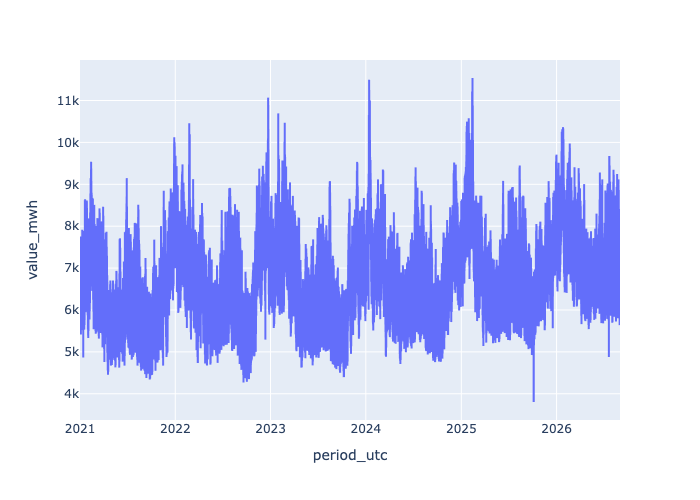

In [27]:
d = con.sql("""
    SELECT period_utc, value_mwh
    FROM eia_raw
    WHERE type = 'D'
    ORDER BY period_utc
""").df()

fig = px.line(d, x="period_utc", y="value_mwh")
fig.show()

can drag an zoom in to check.

In [28]:
#lets take better look with plots
import matplotlib.pyplot as plt
import plotly.graph_objects as go

In [29]:
#threshold 
THRESHOLD = 1000

#flagged hours big jump in, big jump out, opposite directions
#need the sql check to get the data did this above use again
flagged = con.sql(f"""
    WITH demand AS (
        SELECT
            period_utc,
            value_mwh,
            value_mwh - LAG(value_mwh) OVER (ORDER BY period_utc) AS jump_in,
            LEAD(value_mwh) OVER (ORDER BY period_utc) - value_mwh AS jump_out
        FROM eia_raw
        WHERE type = 'D'
    )
    SELECT *
    FROM demand
    WHERE ABS(jump_in) > {THRESHOLD}
      AND ABS(jump_out) > {THRESHOLD}
      AND SIGN(jump_in) != SIGN(jump_out)
    ORDER BY period_utc
""").df()

#full demand series
demand = con.sql("""
    SELECT period_utc, value_mwh
    FROM eia_raw
    WHERE type = 'D'
    ORDER BY period_utc
""").df()

flagged

,period_utc,value_mwh,jump_in,jump_out
0,2021-11-17 20:00:00+00:00,8847.0,1299.0,-1845.0
1,2024-01-11 22:00:00+00:00,6005.0,-2578.0,2514.0
2,2024-08-19 18:00:00+00:00,7866.0,1536.0,-1300.0
3,2026-01-29 09:00:00+00:00,8938.0,1741.0,-2064.0
4,2026-07-20 09:00:00+00:00,4878.0,-1568.0,1112.0


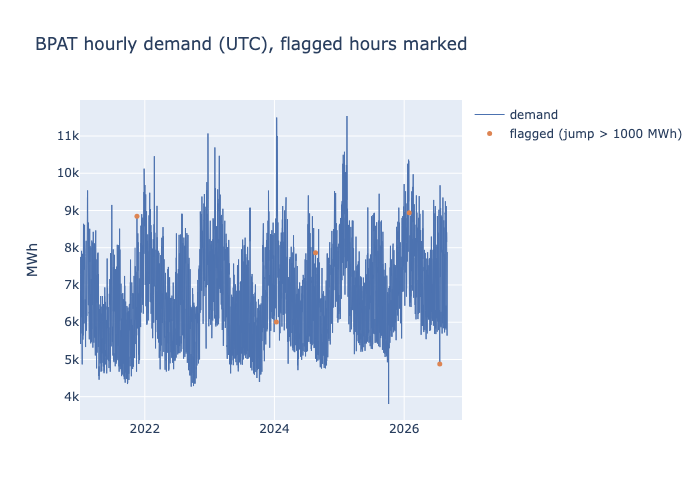

In [30]:
fig = go.Figure()

#all demand as a thin line
fig.add_trace(go.Scatter(
    x=demand["period_utc"], y=demand["value_mwh"],
    mode="lines", name="demand",
    line=dict(width=1, color="#4C72B0"),
))

#flagged hours as dots on top
fig.add_trace(go.Scatter(
    x=flagged["period_utc"], y=flagged["value_mwh"],
    mode="markers", name=f"flagged (jump > {THRESHOLD} MWh)",
    marker=dict(size=5, color="#DD8452"),
))

fig.update_layout(
    title="BPAT hourly demand (UTC), flagged hours marked",
    yaxis_title="MWh",
)
fig.show()

these plots make it easier to see the jumps and 2024-01 and 2026-01 are the worst of the bunch. 

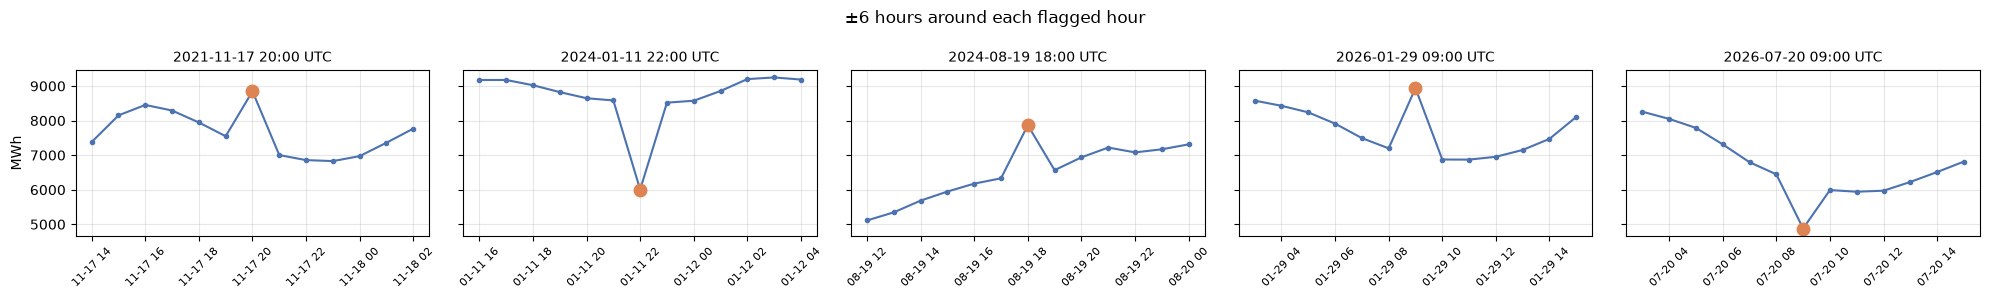

In [31]:
#zoom in 
hours = 6  #how many hours to show on each side
n = len(flagged)

fig, axes = plt.subplots(1, n, figsize=(4 * n, 3), sharey=True)

for ax, (_, row) in zip(axes, flagged.iterrows()):
    t = row["period_utc"]

    #slice the demand series to the window around this hour
    window = demand[
        (demand["period_utc"] >= t - pd.Timedelta(hours=hours)) &
        (demand["period_utc"] <= t + pd.Timedelta(hours=hours))
    ]

    ax.plot(window["period_utc"], window["value_mwh"], marker="o", markersize=3, linewidth=1.5, color="#4C72B0")
    ax.plot(t, row["value_mwh"], "o", markersize=9, color="#DD8452")  #the flagged hour
    ax.set_title(t.strftime("%Y-%m-%d %H:00 UTC"), fontsize=10)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("MWh")
fig.suptitle(f"±{hours} hours around each flagged hour")
fig.tight_layout()
plt.show()

Even with the points there not all are easy to say are spikes. Zooming in does help but lets make smaller windowed plots to look

So given what we see and what I looked up we should flagg 2024-01 and 2026-01 as glitches/spikes. 2012-11 should also be a spike due to the hard change in patter the time causes, it was on a downward trend then jumps high to settle back into the downward trend. The others here could land either way but should be marked as spikes do to the large unusual changes. 

## Decisions on data problems

### What was found

| Problem | Hours | Details | Affects |
|---|---|---|---|
| DF (EIA forecast) missing rows | 72 | 3 full Pacific days: 2021-09-16, 2023-10-25, 2026-08-09 | Benchmark comparison only |
| D (demand) NULL values | 48 | 2 full Pacific days: 2021-09-15, 2023-10-24 (each the day before a DF gap) | Model training |
| D NULL value | 1 | 2021-11-07 05:00 UTC (10 pm Pacific Nov 6), isolated | Model training |
| D glitches | 5 | Single-hour spikes/dips of 1,300–2,600 MWh that reverse the next hour (threshold 1000 MWh) | Model training |

The D and DF gaps sit on back-to-back days in 2021 and 2023, so they're most likely the same reporting outages.

### Decisions

1. **Glitch hours → treat as missing.** The 5 flagged values aren't believable, so set them to NULL and handle them like any other missing hour. Keeping them would teach the model fake spikes.
2. **Isolated missing hours → fill from neighbors (linear interpolation).** This covers the 5 glitch hours and the single NULL hour. Demand changes smoothly hour to hour, so the average of the hours on either side is a safe estimate for one hour. These rows get an `is_filled` flag so they stay traceable.
3. **Full missing days → leave NULL, drop from training.** Filling 24 hours would mean inventing a full daily cycle, and the model would learn from guesses. The rows stay in the table, so the hourly timeline has no holes; the model just skips them.
4. **Missing DF hours → leave NULL, no filling.** DF is only a benchmark. When comparing my forecast to EIA's, compare only on hours where both exist.

Why the 1000 MWh threshold: at 1000, everything flagged was a clear one-hour reversal when plotted. Lower thresholds (500 gives 13 hours) start catching real fast ramps.

### Collect every problem hour in one table
- puts the decisions into the database, so we can apply them with a join instead of re-finding each problem.

In [32]:
con.sql("""
    CREATE OR REPLACE TABLE demand_issues AS

    --glitches: one-hour spikes that reverse the next hour
    WITH demand AS (
        SELECT
            period_utc,
            value_mwh - LAG(value_mwh) OVER (ORDER BY period_utc) AS jump_in,
            LEAD(value_mwh) OVER (ORDER BY period_utc) - value_mwh AS jump_out
        FROM eia_raw
        WHERE type = 'D'
    ),
    glitches AS (
        SELECT period_utc, 'glitch' AS issue, 'fill' AS action
        FROM demand
        WHERE ABS(jump_in) > 1000
          AND ABS(jump_out) > 1000
          AND SIGN(jump_in) != SIGN(jump_out)
    ),

    --NULL demand: an hour with real values on both sides gets filled,
    --an hour inside a longer run of NULLs gets dropped
    d_neighbors AS (
        SELECT
            period_utc,
            value_mwh,
            LAG(value_mwh) OVER (ORDER BY period_utc) AS prev_mwh,
            LEAD(value_mwh) OVER (ORDER BY period_utc) AS next_mwh
        FROM eia_raw
        WHERE type = 'D'
    ),
    null_demand AS (
        SELECT
            period_utc,
            'null_demand' AS issue,
            CASE WHEN prev_mwh IS NULL OR next_mwh IS NULL
                 THEN 'drop' ELSE 'fill' END AS action
        FROM d_neighbors
        WHERE value_mwh IS NULL
    ),

    --missing forecast rows: leave as NULL, skip in the benchmark
    d_hours AS (
        SELECT period_utc FROM eia_raw WHERE type = 'D'
    ),
    df_hours AS (
        SELECT period_utc FROM eia_raw WHERE type = 'DF'
    ),
    missing_df AS (
        SELECT d_hours.period_utc, 'missing_forecast' AS issue, 'leave_null' AS action
        FROM d_hours
        LEFT JOIN df_hours ON d_hours.period_utc = df_hours.period_utc
        WHERE df_hours.period_utc IS NULL
    )

    SELECT * FROM glitches
    UNION ALL
    SELECT * FROM null_demand
    UNION ALL
    SELECT * FROM missing_df
    ORDER BY period_utc
""")

New pieces here:
- UNION ALL stacks the three results on top of each other (they need the same columns in the same order).
- d_neighbors looks up the hour before and after each demand hour **before** filtering to the NULLs (the window has to see the real values next to each gap). A NULL hour with values on both sides is isolated, so it gets `fill`. One with a NULL neighbor is part of a longer gap, so it gets `drop`.
- Why not group by Pacific date? EIA labels hours by their *end*, so the last hour of each missing day falls just after midnight and would land alone on the next date, looking isolated when it isn't.
- `--` starts a SQL comment.

In [33]:
#check: should match the table above (5 glitch fill, 48 drop + 1 fill, 72 leave_null)
con.sql("""
    SELECT issue, action, COUNT(*) AS n_hours
    FROM demand_issues
    GROUP BY issue, action
    ORDER BY issue, action
""")

┌──────────────────┬────────────┬─────────┐
│      issue       │   action   │ n_hours │
│     varchar      │  varchar   │  int64  │
├──────────────────┼────────────┼─────────┤
│ glitch           │ fill       │       5 │
│ missing_forecast │ leave_null │      72 │
│ null_demand      │ drop       │      48 │
│ null_demand      │ fill       │       1 │
└──────────────────┴────────────┴─────────┘

## Clean demand table

Doing two steps:
1. **Reshape** `eia_raw` from long (one row per hour *per type*) to wide (one row per hour, with demand and forecast side by side).
2. **Apply the above decisions** from `demand_issues`. This is blank out glitches, fill the isolated hours, leave the dropped days as NULL.

The result is demand_clean

### Step 1 -> Long to wide

Right now each hour has two rows 'D' and 'DF' as shown:

| period_utc | type | value_mwh |
|---|---|---|
| 2021-01-01 00:00 | D | 6839 |
| 2021-01-01 00:00 | DF | 7125 |

The goal is one row per hour as shown:

| period_utc | demand_mwh_raw | eia_forecast_mwh |
|---|---|---|
| 2021-01-01 00:00 | 6839 | 7125 |

In [34]:
con.sql("""
    CREATE OR REPLACE TABLE demand_wide AS
    SELECT
        period_utc,
        MAX(CASE WHEN type = 'D' THEN value_mwh END) AS demand_mwh_raw,
        MAX(CASE WHEN type = 'DF' THEN value_mwh END) AS eia_forecast_mwh
    FROM eia_raw
    GROUP BY period_utc
    ORDER BY period_utc
""")

con.sql("SELECT * FROM demand_wide LIMIT 5")

┌──────────────────────────┬────────────────┬──────────────────┐
│        period_utc        │ demand_mwh_raw │ eia_forecast_mwh │
│ timestamp with time zone │     double     │      double      │
├──────────────────────────┼────────────────┼──────────────────┤
│ 2021-01-01 00:00:00+00   │         6839.0 │           7125.0 │
│ 2021-01-01 01:00:00+00   │         7233.0 │           7445.0 │
│ 2021-01-01 02:00:00+00   │         7434.0 │           7696.0 │
│ 2021-01-01 03:00:00+00   │         7263.0 │           7527.0 │
│ 2021-01-01 04:00:00+00   │         6999.0 │           7208.0 │
└──────────────────────────┴────────────────┴──────────────────┘

Looks like what I wanted with 1 time row and the 'D' and 'DF' columns for each time

How it is working:
- GROUP BY period_utc squashes the two rows for each hour into one.
- CASE WHEN type = 'D' THEN value_mwh END -> keeps the value only on the D row. On the DF row it gives NULL (no `ELSE` means NULL).
- MAX() is needed because every column in a `GROUP BY` query hs to be grouped or aggregated. Each group has one real value and one NULL, and aggregates skip NULLs, so `MAX` just picks out the one real value (`MIN` would work the same)
- An hour with no DF row (the 72 missing) simply gets NULL in `eia_forecast_mwh`.

DuckDB also has a built-in `PIVOT` statement that does this, but the `CASE WHEN` version works in every SQL database, found out after

In [35]:
#checks one row per hour and NULL counts should match what we found earlier
con.sql("""
    SELECT
        COUNT(*) AS n_rows,           --expect 49,656
        COUNT(DISTINCT period_utc) AS n_hours,          --expect 49,656 (no duplicates)
        COUNT(*) FILTER (WHERE demand_mwh_raw IS NULL) AS null_demand,    --expect 49
        COUNT(*) FILTER (WHERE eia_forecast_mwh IS NULL) AS null_forecast   --expect 72
    FROM demand_wide
""")

┌────────┬─────────┬─────────────┬───────────────┐
│ n_rows │ n_hours │ null_demand │ null_forecast │
│ int64  │  int64  │    int64    │     int64     │
├────────┼─────────┼─────────────┼───────────────┤
│  49656 │   49656 │          49 │            72 │
└────────┴─────────┴─────────────┴───────────────┘

`COUNT(*) FILTER (WHERE ...)` counts only the rows that meet the condition. It's a shorter way to write the `SUM(CASE WHEN ... THEN 1 ELSE 0 END)` used earlier.

Okay so seems to be working for step 1 where we have reshaped to have 1 time row.

### Step 2 Apply the decisions made 

This is done in three steps:
1. **Attach the issues:** LEFT JOIN the demand_wide to the demand issues, so every hour gets its `issue`/`action` (NULL for the 49,600+ hours with no problem) and we have `demand_wide` on the left because every hour has to stay
2. **Blank out the glitches/spike:** set glitch hours to NULL so their bad values can't leak into the fill
3. **Fill:** for `fill` hours, use the average of the hour before and the hour after -> This is linear interpolation for a single missing hour.

Only the missing-forecast issues are left out of the join (they're about the DF column), which stays as is. Leaving them in would also create duplicate rows for any hour with two issues.

In [36]:
con.sql("""
    CREATE OR REPLACE TABLE demand_clean AS

    WITH d_issues AS (
        SELECT period_utc, issue, action
        FROM demand_issues
        WHERE issue != 'missing_forecast'
    ),

    --1. attach issues to every hour
    with_issues AS (
        SELECT
            w.period_utc,
            w.demand_mwh_raw,
            w.eia_forecast_mwh,
            i.issue,
            i.action
        FROM demand_wide AS w
        LEFT JOIN d_issues AS i ON w.period_utc = i.period_utc
    ),

    --2. blank out glitches
    no_glitch AS (
        SELECT
            *,
            CASE WHEN issue = 'glitch' THEN NULL ELSE demand_mwh_raw END AS demand_no_glitch
        FROM with_issues
    ),

    --3. look up neighbors for the fill
    with_neighbors AS (
        SELECT
            *,
            LAG(demand_no_glitch)  OVER (ORDER BY period_utc) AS prev_mwh,
            LEAD(demand_no_glitch) OVER (ORDER BY period_utc) AS next_mwh
        FROM no_glitch
    )

    SELECT
        period_utc,
        CASE WHEN action = 'fill' THEN (prev_mwh + next_mwh) / 2
             ELSE demand_no_glitch END       AS demand_mwh,
        eia_forecast_mwh,
        demand_mwh_raw,                      --original value kept for traceability
        COALESCE(action = 'fill', FALSE)     AS is_filled,
        issue
    FROM with_neighbors
    ORDER BY period_utc
""")

Above query setup and what is going on
- `w` and `i` are short aliases for the two tables I am joining, so `w.period_utc` means "period_utc from demand_wide"
- `SELECT *, <new column>` keeps every existing column and adds one more
- `COALESCE(x, FALSE)` returns `x` unless it's NULL, in which case it returns FALSE and `action = 'fill'` is NULL for hours with no issue, so this turns it into a clean TRUE/FALSE flag
- The fill only works because every `fill` hour is isolated, with real values on both sides. If two fill hours were next to each other, `(prev + next) / 2` would hit a NULL and give NULL

In [37]:
#check none are blank
con.sql("""
    SELECT
        COUNT(*) AS n_rows, 
        COUNT(*) FILTER (WHERE is_filled) AS n_filled, 
        COUNT(*) FILTER (WHERE demand_mwh IS NULL) AS n_null,      
        COUNT(*) FILTER (WHERE is_filled AND demand_mwh IS NULL) AS n_failed_fill  --expect 0
    FROM demand_clean
""")
#expect in order: 49656, 6 for 5 glitches and 1 null hour, 48, 0

┌────────┬──────────┬────────┬───────────────┐
│ n_rows │ n_filled │ n_null │ n_failed_fill │
│ int64  │  int64   │ int64  │     int64     │
├────────┼──────────┼────────┼───────────────┤
│  49656 │        6 │     48 │             0 │
└────────┴──────────┴────────┴───────────────┘

In [38]:
#before and after for each filled hour
con.sql("""
    SELECT period_utc, issue, demand_mwh_raw, demand_mwh
    FROM demand_clean
    WHERE is_filled
    ORDER BY period_utc
""")

┌──────────────────────────┬─────────────┬────────────────┬────────────┐
│        period_utc        │    issue    │ demand_mwh_raw │ demand_mwh │
│ timestamp with time zone │   varchar   │     double     │   double   │
├──────────────────────────┼─────────────┼────────────────┼────────────┤
│ 2021-11-07 05:00:00+00   │ null_demand │           NULL │     7035.5 │
│ 2021-11-17 20:00:00+00   │ glitch      │         8847.0 │     7275.0 │
│ 2024-01-11 22:00:00+00   │ glitch      │         6005.0 │     8551.0 │
│ 2024-08-19 18:00:00+00   │ glitch      │         7866.0 │     6448.0 │
│ 2026-01-29 09:00:00+00   │ glitch      │         8938.0 │     7035.5 │
│ 2026-07-20 09:00:00+00   │ glitch      │         4878.0 │     6218.0 │
└──────────────────────────┴─────────────┴────────────────┴────────────┘

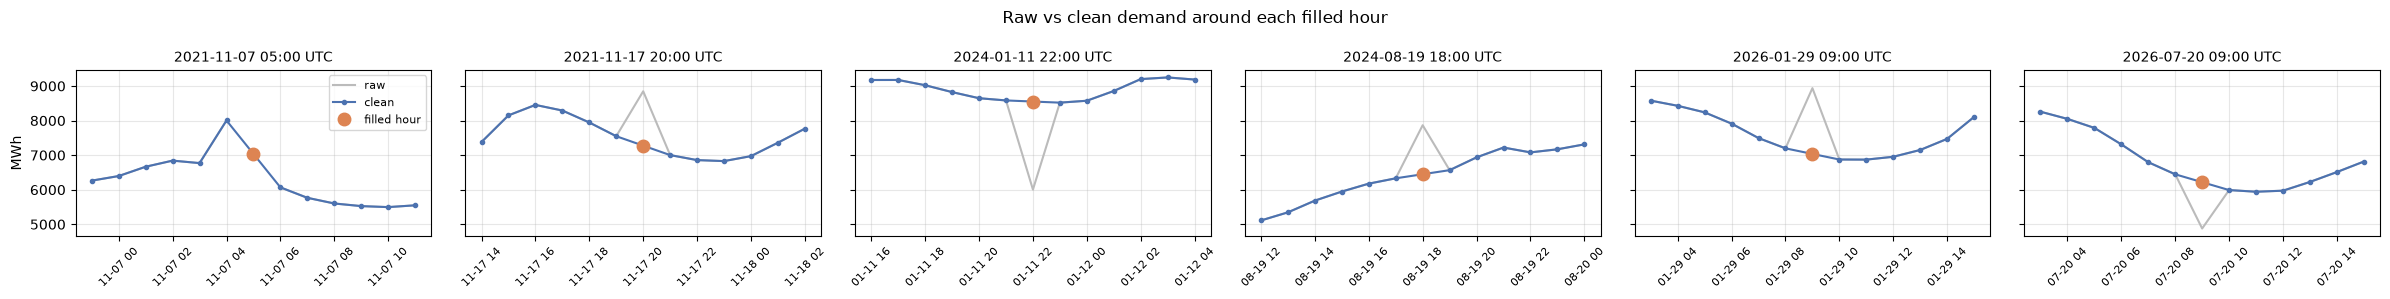

In [39]:
#plot: raw vs clean around each filled hour
clean = con.sql("""
    SELECT period_utc, demand_mwh_raw, demand_mwh, is_filled
    FROM demand_clean
    ORDER BY period_utc
""").df()

filled = clean[clean["is_filled"]]
hours = 6
n = len(filled)

fig, axes = plt.subplots(1, n, figsize=(4 * n, 3), sharey=True)

for ax, (_, row) in zip(axes, filled.iterrows()):
    t = row["period_utc"]
    window = clean[
        (clean["period_utc"] >= t - pd.Timedelta(hours=hours)) &
        (clean["period_utc"] <= t + pd.Timedelta(hours=hours))
    ]

    ax.plot(window["period_utc"], window["demand_mwh_raw"], color="#BBBBBB", linewidth=1.5, label="raw")
    ax.plot(window["period_utc"], window["demand_mwh"], color="#4C72B0", marker="o", markersize=3, linewidth=1.5, label="clean")
    ax.plot(t, row["demand_mwh"], "o", markersize=9, color="#DD8452", label="filled hour")
    ax.set_title(t.strftime("%Y-%m-%d %H:00 UTC"), fontsize=10)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("MWh")
axes[0].legend(fontsize=8)
fig.suptitle("Raw vs clean demand around each filled hour")
fig.tight_layout()
plt.show()

The gray line is the raw data and the blue line is the cleaned data. Where they differ, the orange dot shows the filled value sitting on the smooth trend in place of the spike. The 2021-11-07 hour has no gray point, because it was NULL to begin with and it does make it look like there was a spike there, we are leaving as is since it was not found earlier. 

**Result:** `demand_clean` has one row per hour for 2021-01-01 to 2026-08-31 UTC:
- `demand_mwh`: the cleaned demand. NULL only for the two dropped days, which get filtered out for training.
- `eia_forecast_mwh`: EIA's day-ahead forecast, as reported. NULL for the 72 missing hours.
- `demand_mwh_raw`, `is_filled` and `issue`: a record of what was changed and why. 


Now to the weather data. This will follow similar steps but be done quicker

## Weather Raw

In [40]:
con.sql("DESCRIBE weather_raw").df()

,column_name,column_type,null,key,default,extra
0,location,VARCHAR,YES,None,None,None
1,period_utc,TIMESTAMP WITH TIME ZONE,YES,None,None,None
2,temperature_2m,DOUBLE,YES,None,None,None
3,apparent_temperature,DOUBLE,YES,None,None,None
4,relative_humidity_2m,BIGINT,YES,None,None,None
5,wind_speed_10m,DOUBLE,YES,None,None,None
6,cloud_cover,BIGINT,YES,None,None,None
7,shortwave_radiation,DOUBLE,YES,None,None,None


In [41]:
con.sql(
    """
    SELECT * FROM weather_raw 
    LIMIT 10
    """
)

┌────────────────┬──────────────────────────┬────────────────┬──────────────────────┬──────────────────────┬────────────────┬─────────────┬─────────────────────┐
│    location    │        period_utc        │ temperature_2m │ apparent_temperature │ relative_humidity_2m │ wind_speed_10m │ cloud_cover │ shortwave_radiation │
│    varchar     │ timestamp with time zone │     double     │        double        │        int64         │     double     │    int64    │       double        │
├────────────────┼──────────────────────────┼────────────────┼──────────────────────┼──────────────────────┼────────────────┼─────────────┼─────────────────────┤
│ Vancouver_wash │ 2021-01-01 00:00:00+00   │           48.8 │                 45.2 │                   89 │            6.0 │          97 │                49.0 │
│ Vancouver_wash │ 2021-01-01 01:00:00+00   │           48.0 │                 44.1 │                   91 │            6.5 │          99 │                 4.0 │
│ Vancouver_wash │ 2021-01-0

In [42]:
#check coverage of locations
con.sql("""
    SELECT
        location,
        COUNT(*) AS n_rows,
        COUNT(DISTINCT period_utc) AS n_hours,
        MIN(period_utc) AS first_hour,
        MAX(period_utc) AS last_hour
    FROM weather_raw
    GROUP BY location
    ORDER BY location
""")

┌────────────────┬────────┬─────────┬──────────────────────────┬──────────────────────────┐
│    location    │ n_rows │ n_hours │        first_hour        │        last_hour         │
│    varchar     │ int64  │  int64  │ timestamp with time zone │ timestamp with time zone │
├────────────────┼────────┼─────────┼──────────────────────────┼──────────────────────────┤
│ Eugene         │  49656 │   49656 │ 2021-01-01 00:00:00+00   │ 2026-08-31 23:00:00+00   │
│ Everett        │  49656 │   49656 │ 2021-01-01 00:00:00+00   │ 2026-08-31 23:00:00+00   │
│ Kennewick      │  49656 │   49656 │ 2021-01-01 00:00:00+00   │ 2026-08-31 23:00:00+00   │
│ Vancouver_wash │  49656 │   49656 │ 2021-01-01 00:00:00+00   │ 2026-08-31 23:00:00+00   │
└────────────────┴────────┴─────────┴──────────────────────────┴──────────────────────────┘

Same values as othe table for hours and see beginning and end

In [43]:
#quick duplicate check
con.sql("""
    SELECT location, period_utc, COUNT(*) AS n
    FROM weather_raw
    GROUP BY location, period_utc
    HAVING COUNT(*) > 1
""")

┌──────────┬──────────────────────────┬───────┐
│ location │        period_utc        │   n   │
│ varchar  │ timestamp with time zone │ int64 │
└──────────┴──────────────────────────┴───────┘
                    0 rows                   

No duplicates. 

Query setup: 
- `HAVING` is like WHERE for groups as it filters after the grouping is done, this allows it to use the count()

In [44]:
#look at ranges
#there are more columns in this data so check each
con.sql("""
    SELECT
        location,
        MIN(temperature_2m) AS min_temp, MAX(temperature_2m) AS max_temp,
        MIN(relative_humidity_2m) AS min_hum, MAX(relative_humidity_2m) AS max_hum,
        MIN(wind_speed_10m) AS min_wind, MAX(wind_speed_10m) AS max_wind,
        MIN(cloud_cover) AS min_cloud, MAX(cloud_cover) AS max_cloud,
        MIN(shortwave_radiation) AS min_solar, MAX(shortwave_radiation) AS max_solar
    FROM weather_raw
    GROUP BY location
    ORDER BY location
""").df()

,location,min_temp,max_temp,min_hum,max_hum,min_wind,max_wind,min_cloud,max_cloud,min_solar,max_solar
0,Eugene,13.9,108.9,7,100,0.0,26.3,0,100,0.0,984.0
1,Everett,9.0,103.0,14,100,0.0,29.2,0,100,0.0,935.0
2,Kennewick,1.0,117.1,5,100,0.0,31.8,0,100,0.0,961.0
3,Vancouver_wash,5.7,113.0,13,100,0.0,27.4,0,100,0.0,956.0


Nothing jump out here, just note that spoke has at least 1 negative value

In [45]:
#spikes in weather
con.sql("""
    WITH t AS (
        SELECT
            location,
            period_utc,
            temperature_2m,
            temperature_2m - LAG(temperature_2m)
                OVER (PARTITION BY location ORDER BY period_utc) AS jump
        FROM weather_raw
    )
    SELECT *
    FROM t
    ORDER BY ABS(jump) DESC NULLS LAST
    LIMIT 10
""")

┌────────────────┬──────────────────────────┬────────────────┬─────────────────────┐
│    location    │        period_utc        │ temperature_2m │        jump         │
│    varchar     │ timestamp with time zone │     double     │       double        │
├────────────────┼──────────────────────────┼────────────────┼─────────────────────┤
│ Eugene         │ 2024-07-17 02:00:00+00   │           67.6 │  -18.80000000000001 │
│ Kennewick      │ 2022-02-28 00:00:00+00   │           42.6 │ -15.100000000000001 │
│ Kennewick      │ 2024-08-18 05:00:00+00   │           76.6 │ -14.800000000000011 │
│ Eugene         │ 2026-05-04 03:00:00+00   │           64.2 │ -14.599999999999994 │
│ Vancouver_wash │ 2024-08-18 01:00:00+00   │           67.2 │ -14.399999999999991 │
│ Vancouver_wash │ 2021-06-29 03:00:00+00   │           97.1 │ -13.800000000000011 │
│ Kennewick      │ 2025-05-26 02:00:00+00   │           77.1 │               -13.5 │
│ Vancouver_wash │ 2021-06-29 05:00:00+00   │           74.5 │ -1

Again nothing crazy jumping out here. A change of 20 degrees seems reasonable over an hour.  

Query setup:
- This is similar to the checks for the EIA data but we have different locations so we added a `PARTITION BY location` which runs the window over each location so we don't mix up Eugene and Portland values with each other. 

In [46]:
#do we get many repeated values over a period of time
con.sql("""
    WITH t AS (
        SELECT
            location,
            period_utc,
            temperature_2m,
            temperature_2m = LAG(temperature_2m)
                OVER (PARTITION BY location ORDER BY period_utc) AS same_as_prev
        FROM weather_raw
    ),
    runs AS (
        SELECT *,
            SUM(CASE WHEN same_as_prev THEN 0 ELSE 1 END)
                OVER (PARTITION BY location ORDER BY period_utc) AS run_id
        FROM t
    )
    SELECT
        location,
        MIN(period_utc) AS run_start,
        COUNT(*) AS n_hours,
        ANY_VALUE(temperature_2m) AS value
    FROM runs
    GROUP BY location, run_id
    ORDER BY n_hours DESC
    LIMIT 5
""")

┌───────────┬──────────────────────────┬─────────┬────────┐
│ location  │        run_start         │ n_hours │ value  │
│  varchar  │ timestamp with time zone │  int64  │ double │
├───────────┼──────────────────────────┼─────────┼────────┤
│ Everett   │ 2024-02-06 05:00:00+00   │       8 │   41.2 │
│ Kennewick │ 2022-12-20 06:00:00+00   │       6 │   14.5 │
│ Everett   │ 2021-12-25 11:00:00+00   │       6 │   36.7 │
│ Everett   │ 2025-05-16 08:00:00+00   │       6 │   47.5 │
│ Everett   │ 2025-06-27 08:00:00+00   │       5 │   54.7 │
└───────────┴──────────────────────────┴─────────┴────────┘

Again nothing too crazy here. Times when this is occuring and length could be expected so I wouldn't worry to much about it. 

Query setup:
- Use LAG to check the change
- `same_as_prev` used to check if temperature was same as previour hour and gives TRUE if it was
- SUM is a running sum that adds 1 each time a value changes so when they are the same they have the same run_id and we then group by run_id 
- `GROUP BY run_id` turns the groups in a row with its length so more identical values will have a larger count

Learned this is called 'gaps and islands' - which is good to know. I was thinking if weather isn't changing over many hours that would be suspicious as we usually heat up then cool down in a day so if it didn't happen that would point to an error. 

#### Update here:
- Flagging the longer times for Everett and Kennewick which showed up after switching and are worth flagging/checking done towards the end now. 

In [47]:
#check times, UTC to pacific
con.sql("""
    SELECT
        HOUR(period_utc AT TIME ZONE 'America/Los_Angeles') AS hour_pacific,
        ROUND(AVG(shortwave_radiation), 0) AS avg_solar,
        ROUND(AVG(temperature_2m), 1) AS avg_temp
    FROM weather_raw
    WHERE location = 'Vancouver_wash'
    GROUP BY hour_pacific
    ORDER BY hour_pacific
""").show(max_rows=30)

┌──────────────┬───────────┬──────────┐
│ hour_pacific │ avg_solar │ avg_temp │
│    int64     │  double   │  double  │
├──────────────┼───────────┼──────────┤
│            0 │       0.0 │     50.5 │
│            1 │       0.0 │     49.7 │
│            2 │       0.0 │     49.2 │
│            3 │       0.0 │     48.6 │
│            4 │       0.0 │     48.2 │
│            5 │       0.0 │     48.1 │
│            6 │       1.0 │     47.8 │
│            7 │      20.0 │     48.2 │
│            8 │      73.0 │     49.2 │
│            9 │     167.0 │     51.1 │
│           10 │     275.0 │     53.4 │
│           11 │     374.0 │     55.9 │
│           12 │     448.0 │     58.2 │
│           13 │     488.0 │     60.1 │
│           14 │     488.0 │     61.5 │
│           15 │     454.0 │     62.3 │
│           16 │     384.0 │     62.1 │
│           17 │     290.0 │     60.9 │
│           18 │     192.0 │     59.7 │
│           19 │     108.0 │     58.0 │
│           20 │      41.0 │     56.0 │


Nice solar is 0 or smaller during night hours and larger during day hours

In [48]:
#compare across locations
con.sql("""
    SELECT
        a.location AS loc_a,
        b.location AS loc_b,
        ROUND(CORR(a.temperature_2m, b.temperature_2m), 3) AS temp_corr
    FROM weather_raw AS a
    JOIN weather_raw AS b
        ON a.period_utc = b.period_utc
       AND a.location < b.location
    GROUP BY loc_a, loc_b
    ORDER BY temp_corr DESC
""")

┌───────────┬────────────────┬───────────┐
│   loc_a   │     loc_b      │ temp_corr │
│  varchar  │    varchar     │  double   │
├───────────┼────────────────┼───────────┤
│ Eugene    │ Vancouver_wash │     0.964 │
│ Everett   │ Vancouver_wash │     0.959 │
│ Kennewick │ Vancouver_wash │      0.94 │
│ Eugene    │ Everett        │     0.933 │
│ Everett   │ Kennewick      │     0.929 │
│ Eugene    │ Kennewick      │     0.915 │
└───────────┴────────────────┴───────────┘

They are highly correlated, which is expected as they are in similar areas but they are not THE SAME which is also good. 

Query:
- `CORR` gets the corrlation form -1 to 1 with 1 meaning the same or in lockstep 
- We join the table to itself (self-join), so we can compareing locations temperatures to other locations
- `a.location < b.location` is what keeps us to only 1 pair each meaning Eugene-Portland is one pair and we don't also pair Portland-Eugene. 

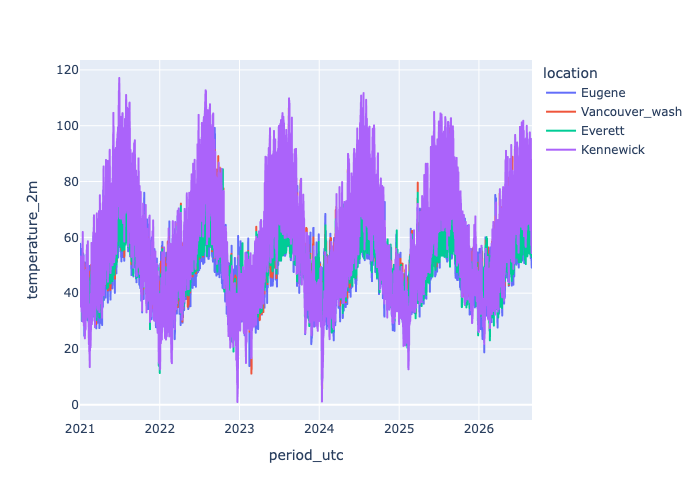

In [49]:
#make a plot of the series
w = con.sql("""
    SELECT period_utc, location, temperature_2m
    FROM weather_raw
    ORDER BY period_utc
""").df()

fig = px.line(w, x="period_utc", y="temperature_2m", color="location")
fig.show()

Quickly see the similarities here and fluctations with time of year

Decisions: 

The weather data was already good and nothing to clean here: 
    No duplicates,
    ranges are physical/reasonable
    jumps seem to be real weather
    nothing is stuck
    time zones are good

The correlation though brings up something interesting. Since I am looking to forecast having a 0.998 correlation does nothing much for me and it is for locations that are nearly the same area - a few miles apart physically. We can change one to add in more coverage to help models. In this pursuit and some digging Portland isn't with BPA but the others are so it makes sense to drop Portland and replace it with another BPA customer. We can use everett WA, this is still PNW area but provides a larger total coverage of the area and stays with BPA

Similar vien - Spokane is not BPA actually but Kennewick is which is near/ similar to Spokane. Since we are already swapping Portland to stay BPA it makes sense to swap Spokane as well. Make these updates in LOCATIONS in src/ then rerun above and to here before final clean. 

Only quickly checking the updated outputs and will flag anything supsicious otherwise outputs/notes will remain as they were. 

CATCHES:
- Everett and Kennewick have longer times of unchanging which are more concerning as one was 8 hours

In [50]:
#look at the catches, just going to look at all weather variables and see if they seem real or are something being stuck
runs = con.sql("""
    WITH t AS (
        SELECT *,
            temperature_2m = LAG(temperature_2m)
                OVER (PARTITION BY location ORDER BY period_utc) AS same_as_prev
        FROM weather_raw
    ),
    runs AS (
        SELECT
            *,
            SUM(CASE WHEN same_as_prev THEN 0 ELSE 1 END)
                OVER (PARTITION BY location ORDER BY period_utc) AS run_id
        FROM t
    )
    SELECT
        location,
        MIN(period_utc) AS run_start,
        MAX(period_utc) AS run_end,
        MIN(period_utc) AT TIME ZONE 'America/Los_Angeles' AS start_pacific,
        COUNT(*) AS n_hours,
        ANY_VALUE(temperature_2m) AS temp_f,
        COUNT(DISTINCT relative_humidity_2m) AS n_humidity_values,
        COUNT(DISTINCT wind_speed_10m) AS n_wind_values,
        ROUND(AVG(relative_humidity_2m), 0) AS avg_humidity,
        ROUND(AVG(cloud_cover), 0) AS avg_cloud
    FROM runs
    GROUP BY location, run_id
    HAVING COUNT(*) >= 5
    ORDER BY n_hours DESC, run_start
""").df()

runs

,location,run_start,run_end,start_pacific,n_hours,temp_f,n_humidity_values,n_wind_values,avg_humidity,avg_cloud
0,Everett,2024-02-06 05:00:00+00:00,2024-02-06 12:00:00+00:00,2024-02-05 21:00:00,8,41.2,2,6,100.0,100.0
1,Everett,2021-12-25 11:00:00+00:00,2021-12-25 16:00:00+00:00,2021-12-25 03:00:00,6,36.7,4,6,98.0,100.0
2,Kennewick,2022-12-20 06:00:00+00:00,2022-12-20 11:00:00+00:00,2022-12-19 22:00:00,6,14.5,4,6,80.0,100.0
3,Everett,2025-05-16 08:00:00+00:00,2025-05-16 13:00:00+00:00,2025-05-16 01:00:00,6,47.5,4,3,96.0,100.0
4,Kennewick,2021-01-25 12:00:00+00:00,2021-01-25 16:00:00+00:00,2021-01-25 04:00:00,5,30.7,4,4,93.0,99.0
5,Everett,2021-11-19 05:00:00+00:00,2021-11-19 09:00:00+00:00,2021-11-18 21:00:00,5,41.2,2,5,99.0,100.0
6,Vancouver_wash,2023-01-19 12:00:00+00:00,2023-01-19 16:00:00+00:00,2023-01-19 04:00:00,5,36.9,2,4,99.0,100.0
7,Everett,2023-02-20 05:00:00+00:00,2023-02-20 09:00:00+00:00,2023-02-19 21:00:00,5,43.0,1,4,99.0,100.0
8,Kennewick,2024-12-17 05:00:00+00:00,2024-12-17 09:00:00+00:00,2024-12-16 21:00:00,5,37.9,2,5,91.0,100.0
9,Everett,2025-06-27 08:00:00+00:00,2025-06-27 12:00:00+00:00,2025-06-27 01:00:00,5,54.7,3,5,91.0,100.0


The other weather metrics change so this is likely real weather. Also see it was a lot of cloud and humidity which would make it likely to stay more consistent. 

Query:
Trying to see if it was actually stuck. If stuck then everything should freeze not just the temperature
- SELCT * at beginning keeps all weather to be checked 
- COUNT(DISTINCT) counts the different values a column takes for each run of time so a 1 means it didn't move
- HAVING COUNT keeps the runs that of 5 or more which filters to the temperatures flagged before

In [51]:
for _, r in runs.iterrows():
    print(f"--- {r['location']}: {r['n_hours']} hours at {r['temp_f']} °F, starting {r['start_pacific']} Pacific")
    display(con.sql(f"""
        SELECT
            period_utc AT TIME ZONE 'America/Los_Angeles' AS pacific,
            temperature_2m       AS temp_f,
            apparent_temperature AS feels_like_f,
            relative_humidity_2m AS humidity_pct,
            wind_speed_10m       AS wind_mph,
            cloud_cover          AS cloud_pct,
            shortwave_radiation  AS solar_wm2
        FROM weather_raw
        WHERE location = '{r['location']}'
          AND period_utc BETWEEN TIMESTAMPTZ '{r['run_start']}' - INTERVAL 2 HOUR
                             AND TIMESTAMPTZ '{r['run_end']}'   + INTERVAL 2 HOUR
        ORDER BY period_utc
    """).df())

--- Everett: 8 hours at 41.2 °F, starting 2024-02-05 21:00:00 Pacific


,pacific,temp_f,feels_like_f,humidity_pct,wind_mph,cloud_pct,solar_wm2
0,2024-02-05 19:00:00,40.9,36.8,100,4.4,100,0.0
1,2024-02-05 20:00:00,41.0,37.2,100,3.8,100,0.0
2,2024-02-05 21:00:00,41.2,37.5,99,3.4,100,0.0
3,2024-02-05 22:00:00,41.2,37.3,100,4.0,100,0.0
4,2024-02-05 23:00:00,41.2,37.6,100,3.3,100,0.0
5,2024-02-06 00:00:00,41.2,37.7,100,2.9,100,0.0
6,2024-02-06 01:00:00,41.2,37.5,100,3.7,100,0.0
7,2024-02-06 02:00:00,41.2,37.7,100,3.3,100,0.0
8,2024-02-06 03:00:00,41.2,37.9,100,2.9,100,0.0
9,2024-02-06 04:00:00,41.2,38.0,99,2.6,100,0.0


--- Everett: 6 hours at 36.7 °F, starting 2021-12-25 03:00:00 Pacific


,pacific,temp_f,feels_like_f,humidity_pct,wind_mph,cloud_pct,solar_wm2
0,2021-12-25 01:00:00,36.4,31.5,98,4.1,100,0.0
1,2021-12-25 02:00:00,37.2,31.4,95,6.2,86,0.0
2,2021-12-25 03:00:00,36.7,31.4,97,4.9,100,0.0
3,2021-12-25 04:00:00,36.7,31.1,100,5.9,100,0.0
4,2021-12-25 05:00:00,36.7,29.7,97,8.9,100,0.0
5,2021-12-25 06:00:00,36.7,28.9,99,11.3,100,0.0
6,2021-12-25 07:00:00,36.7,28.6,97,11.6,100,0.0
7,2021-12-25 08:00:00,36.7,28.3,98,12.7,100,0.0
8,2021-12-25 09:00:00,36.9,28.2,95,13.2,100,14.0
9,2021-12-25 10:00:00,37.3,28.1,94,14.3,100,55.0


--- Kennewick: 6 hours at 14.5 °F, starting 2022-12-19 22:00:00 Pacific


...

,pacific,temp_f,feels_like_f,humidity_pct,wind_mph,cloud_pct,solar_wm2
0,2025-06-26 23:00:00,56.7,56.2,96,5.6,100,0.0
1,2025-06-27 00:00:00,55.5,54.5,96,5.5,100,0.0
2,2025-06-27 01:00:00,54.7,53.8,94,4.3,100,0.0
3,2025-06-27 02:00:00,54.7,54.3,91,2.4,100,0.0
4,2025-06-27 03:00:00,54.7,54.8,90,1.1,100,0.0
5,2025-06-27 04:00:00,54.7,54.7,91,1.3,100,0.0
6,2025-06-27 05:00:00,54.7,55.0,91,0.9,100,0.0
7,2025-06-27 06:00:00,54.9,55.1,94,2.0,100,2.0
8,2025-06-27 07:00:00,55.3,55.2,93,2.5,100,19.0


--- Eugene: 5 hours at 39.7 °F, starting 2025-12-20 01:00:00 Pacific


,pacific,temp_f,feels_like_f,humidity_pct,wind_mph,cloud_pct,solar_wm2
0,2025-12-19 23:00:00,40.1,34.4,92,6.8,33,0.0
1,2025-12-20 00:00:00,39.9,34.4,92,6.4,30,0.0
2,2025-12-20 01:00:00,39.7,33.6,93,7.5,33,0.0
3,2025-12-20 02:00:00,39.7,33.5,92,7.6,34,0.0
4,2025-12-20 03:00:00,39.7,33.5,91,7.7,35,0.0
5,2025-12-20 04:00:00,39.7,33.2,89,8.2,15,0.0
6,2025-12-20 05:00:00,39.7,33.1,86,8.0,18,0.0
7,2025-12-20 06:00:00,39.3,32.6,84,8.0,20,0.0
8,2025-12-20 07:00:00,38.9,32.0,82,8.2,15,0.0


--- Kennewick: 5 hours at 30.2 °F, starting 2026-01-22 17:00:00 Pacific


,pacific,temp_f,feels_like_f,humidity_pct,wind_mph,cloud_pct,solar_wm2
0,2026-01-22 15:00:00,31.6,25.8,75,2.5,100,84.0
1,2026-01-22 16:00:00,30.4,24.5,80,2.6,100,52.0
2,2026-01-22 17:00:00,30.2,24.1,81,3.1,100,7.0
3,2026-01-22 18:00:00,30.2,24.0,82,3.4,100,0.0
4,2026-01-22 19:00:00,30.2,23.8,80,3.9,100,0.0
5,2026-01-22 20:00:00,30.2,23.8,82,4.0,100,0.0
6,2026-01-22 21:00:00,30.2,23.9,83,3.7,100,0.0
7,2026-01-22 22:00:00,30.8,24.3,84,4.7,100,0.0
8,2026-01-22 23:00:00,30.7,24.0,86,5.0,100,0.0


## Weather long to wide

`weather_raw` has one row per hour *per location* (4 rows per hour). The model needs one row per hour, so each location's weather becomes its own set of columns:

| period_utc | everett_temp_f | kennewick_temp_f | ... |
|---|---|---|---|

Same reshape as the demand table, but with 4 locations × 6 variables = 24 new columns.

### Step 1 -> The `CASE WHEN` way, for one variable
Same pattern as `demand_wide`, done for temperature only, to show how it scales:

In [52]:
con.sql("""
    SELECT
        period_utc,
        MAX(CASE WHEN location = 'Eugene' THEN temperature_2m END) AS eugene_temp_f,
        MAX(CASE WHEN location = 'Everett' THEN temperature_2m END) AS everett_temp_f,
        MAX(CASE WHEN location = 'Kennewick' THEN temperature_2m END) AS kennewick_temp_f,
        MAX(CASE WHEN location = 'Vancouver_wash' THEN temperature_2m END) AS vancouver_wash_temp_f
    FROM weather_raw
    GROUP BY period_utc
    ORDER BY period_utc
    LIMIT 5
""")

┌──────────────────────────┬───────────────┬────────────────┬──────────────────┬───────────────────────┐
│        period_utc        │ eugene_temp_f │ everett_temp_f │ kennewick_temp_f │ vancouver_wash_temp_f │
│ timestamp with time zone │    double     │     double     │      double      │        double         │
├──────────────────────────┼───────────────┼────────────────┼──────────────────┼───────────────────────┤
│ 2021-01-01 00:00:00+00   │          48.5 │           46.9 │             45.3 │                  48.8 │
│ 2021-01-01 01:00:00+00   │          47.7 │           46.6 │             42.8 │                  48.0 │
│ 2021-01-01 02:00:00+00   │          46.8 │           46.6 │             39.9 │                  47.7 │
│ 2021-01-01 03:00:00+00   │          46.0 │           46.5 │             39.1 │                  48.2 │
│ 2021-01-01 04:00:00+00   │          45.5 │           45.9 │             38.4 │                  48.4 │
└──────────────────────────┴───────────────┴───────────

That's 4 lines for one variable, so all six would need 24 nearly identical lines, and adding a location means editing six of them. It works, but it's easy to make a copy-paste mistake.

### Step 2 -> DuckDB's `PIVOT`, for all variables
`PIVOT` writes those `CASE WHEN` lines for you:

In [53]:
con.sql("""
    CREATE OR REPLACE TABLE weather_wide AS
    PIVOT (
        SELECT
            period_utc,
            lower(location) AS location,
            temperature_2m,
            apparent_temperature,
            relative_humidity_2m,
            wind_speed_10m,
            cloud_cover,
            shortwave_radiation
        FROM weather_raw
    )
    ON location
    USING
        MAX(temperature_2m) AS temp_f,
        MAX(apparent_temperature) AS feels_like_f,
        MAX(relative_humidity_2m) AS humidity_pct,
        MAX(wind_speed_10m) AS wind_mph,
        MAX(cloud_cover) AS cloud_pct,
        MAX(shortwave_radiation) AS solar_wm2
    GROUP BY period_utc
    ORDER BY period_utc
""")

con.sql("DESCRIBE weather_wide").df()[["column_name", "column_type"]]

,column_name,column_type
0,period_utc,TIMESTAMP WITH TIME ZONE
1,eugene_temp_f,DOUBLE
2,eugene_feels_like_f,DOUBLE
3,eugene_humidity_pct,BIGINT
4,eugene_wind_mph,DOUBLE
5,eugene_cloud_pct,BIGINT
6,eugene_solar_wm2,DOUBLE
7,everett_temp_f,DOUBLE
8,everett_feels_like_f,DOUBLE
9,everett_humidity_pct,BIGINT


How it is working:
- `PIVOT ( ... )`: the data to reshape. The subquery lowercases the location names so the new columns come out as `everett_...` instead of `Everett_...`.
- `ON location`: each distinct location becomes its own group of columns.
- `USING MAX(x) AS name`: what goes in each new column. Column names are built as `<location>_<name>`, e.g. `everett_temp_f`. `MAX` works for the same reason as before: there's exactly one value per location per hour.
- `GROUP BY period_utc`: one row per hour.

Units are in the names (`_f`, `_pct`, `_mph`, `_wm2`) so nobody has to guess later. `solar_wm2` is incoming sunlight in watts per square meter.

`PIVOT` is DuckDB-specific (some other databases have their own versions). The `CASE WHEN` pattern in Step 1 is the portable one.

In [54]:
#check one row per hour, no duplicates
con.sql("""
    SELECT
        COUNT(*) AS n_rows,   --expect 49,656
        COUNT(DISTINCT period_utc) AS n_hours   --expect 49,656
    FROM weather_wide
""")

┌────────┬─────────┐
│ n_rows │ n_hours │
│ int64  │  int64  │
├────────┼─────────┤
│  49656 │   49656 │
└────────┴─────────┘

In [55]:
#SUMMARIZE profiles every column at once: min, max, mean, null %, and more
con.sql("SUMMARIZE weather_wide").df()[["column_name", "min", "max", "avg", "null_percentage"]]

,column_name,min,max,avg,null_percentage
0,period_utc,2021-01-01 00:00:00+00,2026-08-31 23:00:00+00,2023-11-01 11:30:00+00,0.0
1,eugene_temp_f,13.9,108.9,53.177479055904705,0.0
2,eugene_feels_like_f,5.4,109.8,50.13511559529592,0.0
3,eugene_humidity_pct,7,100,76.44747865313356,0.0
4,eugene_wind_mph,0.0,26.3,5.05440228773964,0.0
5,eugene_cloud_pct,0,100,60.0942282906396,0.0
6,eugene_solar_wm2,0.0,984.0,169.8705695182858,0.0
7,everett_temp_f,9.0,103.0,51.55698203641049,0.0
8,everett_feels_like_f,-0.6,109.8,48.43818269695492,0.0
9,everett_humidity_pct,14,100,80.70923956822942,0.0


`SUMMARIZE` is a quick way to sanity-check a wide table without writing one query per column. Things to look for:
- `null_percentage` should be 0 for every column (the weather pull had no gaps).
- Ranges should make physical sense: humidity and cloud cover between 0 and 100, and solar at 0 at night.
- Kennewick (east of the Cascades) has both extremes: the coldest minimum (1.0 °F, the December 2022 Arctic outbreak) and the hottest maximum (117.1 °F, 2021-06-29 during the heat dome). Records like these are real and worth keeping, since they're exactly the extremes a grid operator cares about.

## Join demand and weather

Both tables now have one row per hour, keyed on `period_utc`, so they can be joined.

`demand_clean` goes on the **left**. Every demand hour has to stay, and if weather were somehow missing for an hour, the `LEFT JOIN` would show it as NULL instead of dropping the row (the same reason as for the missing DF hours).

In [56]:
con.sql("""
    CREATE OR REPLACE TABLE model_hourly AS
    SELECT
        d.period_utc,
        d.demand_mwh,
        d.eia_forecast_mwh,
        d.is_filled,
        w.* EXCLUDE (period_utc)
    FROM demand_clean AS d
    LEFT JOIN weather_wide AS w ON d.period_utc = w.period_utc
    ORDER BY d.period_utc
""")

con.sql("SELECT * FROM model_hourly LIMIT 5")

┌──────────────────────────┬────────────┬──────────────────┬───────────┬───────────────┬─────────────────────┬─────────────────────┬─────────────────┬──────────────────┬──────────────────┬────────────────┬──────────────────────┬──────────────────────┬──────────────────┬───────────────────┬───────────────────┬──────────────────┬────────────────────────┬────────────────────────┬────────────────────┬─────────────────────┬─────────────────────┬───────────────────────┬─────────────────────────────┬─────────────────────────────┬─────────────────────────┬──────────────────────────┬──────────────────────────┐
│        period_utc        │ demand_mwh │ eia_forecast_mwh │ is_filled │ eugene_temp_f │ eugene_feels_like_f │ eugene_humidity_pct │ eugene_wind_mph │ eugene_cloud_pct │ eugene_solar_wm2 │ everett_temp_f │ everett_feels_like_f │ everett_humidity_pct │ everett_wind_mph │ everett_cloud_pct │ everett_solar_wm2 │ kennewick_temp_f │ kennewick_feels_like_f │ kennewick_humidity_pct │ kennewick_w

Above query setup and what is going on:
- `w.* EXCLUDE (period_utc)` takes every weather column except the timestamp, which `d.period_utc` already provides. Without the `EXCLUDE`, the table would have two `period_utc` columns.
- `demand_mwh_raw` and `issue` are left out on purpose. They're audit columns and stay in `demand_clean`, while `model_hourly` holds only what the model and the forecast comparison need.

In [57]:
#checks
con.sql("""
    SELECT
        COUNT(*) AS n_rows,              --expect 49,656
        COUNT(DISTINCT period_utc) AS n_hours,             --expect 49,656
        COUNT(*) FILTER (WHERE vancouver_wash_temp_f IS NULL) AS missing_weather,     --expect 0
        COUNT(*) FILTER (WHERE demand_mwh IS NULL) AS no_demand,           --expect 48 (dropped days)
        COUNT(*) FILTER (WHERE eia_forecast_mwh IS NULL) AS no_forecast,         --expect 72
        COUNT(*) FILTER (WHERE demand_mwh IS NOT NULL) AS usable_for_training  --expect 49,608
    FROM model_hourly
""")

┌────────┬─────────┬─────────────────┬───────────┬─────────────┬─────────────────────┐
│ n_rows │ n_hours │ missing_weather │ no_demand │ no_forecast │ usable_for_training │
│ int64  │  int64  │      int64      │   int64   │    int64    │        int64        │
├────────┼─────────┼─────────────────┼───────────┼─────────────┼─────────────────────┤
│  49656 │   49656 │               0 │        48 │          72 │               49608 │
└────────┴─────────┴─────────────────┴───────────┴─────────────┴─────────────────────┘

### Does the join make sense?
demand should rise in cold weather (heating) and somewhat in hot weather (cooling), giving a U or hockey-stick shape against temperature. If the join had lined up the wrong hours, this shape would be smeared out so lets plot to see this shape

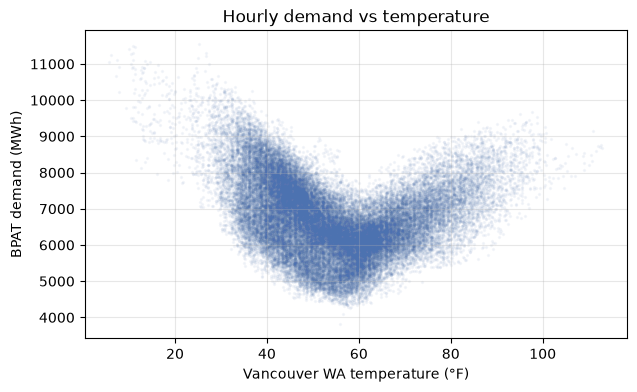

In [58]:
check = con.sql("""
    SELECT vancouver_wash_temp_f, demand_mwh
    FROM model_hourly
    WHERE demand_mwh IS NOT NULL
""").df()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(check["vancouver_wash_temp_f"], check["demand_mwh"], s=2, alpha=0.05, color="#4C72B0")
ax.set_xlabel("Vancouver WA temperature (°F)")
ax.set_ylabel("BPAT demand (MWh)")
ax.set_title("Hourly demand vs temperature")
ax.grid(alpha=0.3)
plt.show()

Each dot is one hour. `alpha=0.05` makes the dots mostly transparent, so dense areas show up darker. Without it, 49,000 points just look like a solid blob.

The shape to look for: demand is highest at the cold end, lowest around 55–65 °F, and rises a little at the hot end. BPA's region heats more than it cools, so the cold side should be steeper. This is seen so the join seems good

## Summary

Tables built in `grid.duckdb` by this notebook:

| Table | One row per | What it's for |
|---|---|---|
| `demand_issues` | problem hour | Every data problem found and the decision for it |
| `demand_wide` | hour | EIA demand + forecast side by side, uncleaned |
| `demand_clean` | hour | Glitches removed, isolated gaps filled, with audit columns `demand_mwh_raw`, `is_filled`, `issue` |
| `weather_wide` | hour | 4 locations × 6 weather variables |
| `model_hourly` | hour | **The modeling table**: clean demand, EIA forecast, and all weather columns |

Key numbers: 49,656 hours (2021-01-01 to 2026-08-31 UTC), 49,608 usable for training, 6 filled hours, 48 dropped (two full days), 72 hours without an EIA forecast.


In [59]:
#release the database so other notebooks and load_data.py can open it
con.close()